# 02 – Hồi quy tuyến tính (Linear Regression)

- **Thành viên phụ trách:** Hiếu
- **Đề tài:** Retail / Sales Intelligence – Phân tích hiệu quả bán hàng của Superstore (2014–2017)
- **Câu hỏi nghiên cứu số 5:** *Mô hình hồi quy tuyến tính ước lượng kết quả bán hàng tốt đến đâu trên dữ liệu chưa dùng để huấn luyện, và những yếu tố nào có liên hệ rõ nhất?*
- **Dữ liệu đầu vào:** `data_cleaned/superstore_clean.csv` (9.993 dòng × 21 cột, do Hưng bàn giao sau khi làm sạch)

---

### M1. Xác nhận loại mô hình hồi quy (Câu trả lời trao đổi với giảng viên)
- **Định hướng lựa chọn:** Nhóm sử dụng **Hồi quy đa biến (Multiple Linear Regression)** làm mô hình phân tích chính. Lý do: Kết quả bán hàng (`Sales`) trong ngành bán lẻ chịu tác động đồng thời của nhiều yếu tố như số lượng mua (`Quantity`), tỷ lệ chiết khấu (`Discount`), đặc thù nhóm sản phẩm (`Sub-Category`), khu vực địa lý (`Region`), và phân khúc khách hàng (`Segment`).
- **Đối chiếu bổ sung:** Để trả lời trọn vẹn câu hỏi phương pháp, nhóm đồng thời xây dựng mô hình **Hồi quy đơn biến (Simple Linear Regression)** với `Quantity` để làm bước đệm so sánh, qua đó đánh giá định lượng giá trị tăng thêm khi mở rộng từ đơn biến sang đa biến.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Cấu hình hiển thị và đồ thị
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# Xác định đường dẫn thư mục gốc độc lập với vị trí thực thi
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_raw").is_dir())
CLEAN_PATH = ROOT / "data_cleaned" / "superstore_clean.csv"

if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"Chưa tìm thấy {CLEAN_PATH}. Hãy hoàn thành notebook 01 trước.")

df = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig")
print(f"Đã nạp dữ liệu sạch thành công: {df.shape[0]:,} dòng × {df.shape[1]} cột.")

# Chuyển đổi cột ngày và trích xuất năm, tháng phục vụ phân tích xu hướng thời gian
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Order_Year"] = df["Order Date"].dt.year
df["Order_Month"] = df["Order Date"].dt.month
df[["Order ID", "Order Date", "Category", "Sub-Category", "Sales", "Quantity", "Discount", "Profit"]].head()

Đã nạp dữ liệu sạch thành công: 9,993 dòng × 21 cột.


,Order ID,Order Date,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,CA-2016-152156,2016-11-08,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,CA-2016-152156,2016-11-08,Furniture,Chairs,731.9400,3,0.00,219.5820
2,CA-2016-138688,2016-06-12,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,US-2015-108966,2015-10-11,Furniture,Tables,957.5775,5,0.45,-383.0310
4,US-2015-108966,2015-10-11,Office Supplies,Storage,22.3680,2,0.20,2.5164


## 1. Xác định mô hình & Lựa chọn biến (M2)

### Biến mục tiêu $Y$:
- **`Sales` (Doanh thu mặt hàng):** Giá trị giao dịch bằng tiền (USD) của từng dòng sản phẩm trong đơn hàng. Đây là biến kết quả kinh doanh quan trọng nhất phản ánh quy mô bán hàng của Superstore.

### Bảng các biến đầu vào $X$ và lý do lựa chọn:

| Tên biến | Loại biến | Vai trò & Lý do kinh doanh |
| :--- | :--- | :--- |
| **`Quantity`** | Định lượng (Số nguyên) | Số lượng sản phẩm khách mua trong dòng đơn hàng. Về lý thuyết kinh tế, số lượng tỷ lệ thuận với tổng giá trị tiền bán. |
| **`Discount`** | Định lượng (Tỷ lệ 0–0.8) | Mức chiết khấu giảm giá. Tỷ lệ giảm giá trực tiếp làm giảm giá bán thực thu trên mỗi sản phẩm. |
| **`Sub-Category`** | Định danh (17 nhóm) | Nhóm sản phẩm chi tiết (Copiers, Machines, Tables, Paper...). Đây là yếu tố quyết định thang giá gốc của sản phẩm. |
| **`Category`** | Định danh (3 ngành hàng) | Nhóm ngành hàng lớn (Technology, Furniture, Office Supplies). |
| **`Region`** | Định danh (4 vùng) | Khu vực địa lý (Central, East, South, West), phản ánh sức mua và cơ cấu thị trường theo vùng. |
| **`Segment`** | Định danh (3 phân khúc) | Phân khúc khách hàng (Consumer, Corporate, Home Office), đại diện cho quy mô và hành vi mua sắm khác nhau. |
| **`Ship Mode`** | Định danh (4 hình thức) | Phương thức vận chuyển (Standard Class, Second Class, First Class, Same Day). |
| **`Order_Year`** | Định lượng / Thứ tự | Năm đặt hàng (2014–2017), kiểm soát xu hướng tăng trưởng kinh doanh qua các năm. |
| **`Order_Month`** | Định lượng / Mùa vụ | Tháng đặt hàng (1–12), kiểm soát tính mùa vụ bán lẻ (đặc biệt các tháng cao điểm cuối năm). |

### Ràng buộc DoD – Các biến loại trừ và lý do kỹ thuật:
1. **`Profit`:** Tuyệt đối **không** đưa vào $X$. Lợi nhuận là biến kết quả được tính toán trực tiếp từ `Sales` cùng các chi phí; đưa `Profit` vào sẽ vi phạm nguyên tắc rò rỉ biến mục tiêu (target leakage).
2. **`Row ID`, `Order ID`, `Customer ID`, `Customer Name`, `Product ID`, `Product Name`, `Postal Code`:** Các mã định danh danh nghĩa riêng lẻ (ID/Tên riêng) không có tính quy luật tổng quát hóa; đưa vào sẽ làm mô hình ghi nhớ máy móc (overfitting) hoặc bùng nổ số chiều dữ liệu.
3. **`Order Date`, `Ship Date` (dạng thô):** Không đưa chuỗi ngày thô vào mô hình OLS; đã trích xuất thành các thuộc tính chu kỳ có ý nghĩa kinh tế (`Order_Year`, `Order_Month`).

In [2]:
# Danh sách các biến đầu vào X và biến đích Y
features_num = ["Quantity", "Discount", "Order_Year", "Order_Month"]
features_cat = ["Sub-Category", "Region", "Segment", "Ship Mode"]

X = df[features_num + features_cat].copy()
y = df["Sales"].copy()
groups = df["Order ID"].copy()

print(f"Ma trận X gồm {X.shape[1]} biến ({len(features_num)} biến số, {len(features_cat)} biến phân loại).")
print(f"Vector y: Sales có trung bình ${y.mean():.2f}, độ lệch chuẩn ${y.std():.2f}, min ${y.min():.2f}, max ${y.max():.2f}.")

Ma trận X gồm 8 biến (4 biến số, 4 biến phân loại).
Vector y: Sales có trung bình $229.85, độ lệch chuẩn $623.28, min $0.44, max $22638.48.


## 2. Chia tập huấn luyện và kiểm tra (M3)

### Vấn đề rò rỉ dữ liệu khi một đơn hàng có nhiều dòng:
Trong tập dữ liệu Superstore, **một đơn hàng (`Order ID`) thường chứa nhiều mặt hàng (tối đa 14 dòng)**. 
- Nếu chia ngẫu nhiên thuần túy theo từng dòng (`train_test_split`), các mặt hàng trong cùng một đơn sẽ bị chia rẽ sang cả tập huấn luyện và tập kiểm tra.
- Do các mặt hàng trong cùng một đơn chia sẻ chung khách hàng, ngày mua, hành vi giỏ hàng và chính sách chiết khấu, mô hình sẽ bị **"rò rỉ dữ liệu" (data leakage)**, dẫn đến việc đánh giá độ chính xác bị thổi phồng một cách thiếu khách quan.

### Giải pháp kỹ thuật:
- Áp dụng **`GroupShuffleSplit`** phân cụm theo **`Order ID`**.
- **Tỷ lệ chia:** 80% số đơn hàng vào tập huấn luyện (Train), 20% số đơn hàng vào tập kiểm tra (Test).
- **`random_state = 42`:** Cố định hạt giống ngẫu nhiên để mọi lần chạy lại đều cho kết quả hoàn toàn trùng khớp 100%.

In [3]:
# Khởi tạo bộ chia nhóm GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

train_orders = groups.iloc[train_idx].nunique()
test_orders = groups.iloc[test_idx].nunique()

print(f"- Tập huấn luyện (Train): {len(X_train):,} dòng ({train_orders:,} đơn hàng, chiếm {train_orders/groups.nunique():.1%})")
print(f"- Tập kiểm tra (Test):      {len(X_test):,} dòng ({test_orders:,} đơn hàng, chiếm {test_orders/groups.nunique():.1%})")

# Kiểm tra giao thoa đơn hàng giữa 2 tập
leakage_check = set(groups.iloc[train_idx]).intersection(set(groups.iloc[test_idx]))
print(f"- Số đơn hàng trùng giữa Train và Test: {len(leakage_check)} đơn (Đạt chuẩn 0% rò rỉ).")

- Tập huấn luyện (Train): 7,958 dòng (4,007 đơn hàng, chiếm 80.0%)
- Tập kiểm tra (Test):      2,035 dòng (1,002 đơn hàng, chiếm 20.0%)
- Số đơn hàng trùng giữa Train và Test: 0 đơn (Đạt chuẩn 0% rò rỉ).


## 3. Mô hình mốc so sánh (Baseline Model) (M4)

Để đánh giá khách quan xem mô hình hồi quy tuyến tính có thực sự học được quy luật từ dữ liệu hay không, ta bắt buộc phải so sánh với một **mô hình mốc cơ sở (Baseline)**.
- Nhóm sử dụng **`DummyRegressor(strategy='mean')`**.
- Mô hình này đưa ra dự đoán đơn giản bằng giá trị trung bình doanh số của tập huấn luyện ($\hat{y} = \bar{y}_{train}$) cho mọi quan sát trong tương lai.
- Nếu một mô hình hồi quy học máy không vượt qua được mốc này về các chỉ số sai số ($MAE$, $RMSE$) hoặc có $R^2 \le 0$, mô hình đó không có giá trị thực tiễn.

In [4]:
# Huấn luyện mô hình mốc DummyRegressor
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)
mean_sales_train = dummy_model.constant_[0][0]
print(f"Dự đoán cố định của mô hình mốc: ${mean_sales_train:.2f} USD cho mọi dòng đơn.")

Dự đoán cố định của mô hình mốc: $227.67 USD cho mọi dòng đơn.


## 4. Huấn luyện mô hình hồi quy tuyến tính với Pipeline (M5)

### Nguyên tắc thiết kế Pipeline chống rò rỉ dữ liệu (DoD):
- Mã hóa biến phân loại One-Hot (`OneHotEncoder`) được đặt bên trong `Pipeline` thông qua `ColumnTransformer`.
- Tham số `drop='first'` được áp dụng để loại bỏ một cột cơ sở của mỗi biến phân loại, tránh hiện tượng bẫy đa cộng tuyến hoàn hảo (*Dummy Variable Trap*).
- **Cực kỳ quan trọng:** Bộ biến đổi chỉ học cấu trúc danh mục (`fit`) trên tập huấn luyện `X_train`, sau đó áp dụng biến đổi (`transform`) trên `X_test`. Tập kiểm tra tuyệt đối không can thiệp vào quá trình huấn luyện.

### Hai cấu hình mô hình được huấn luyện:
1. **Mô hình Hồi quy đơn biến (Simple LR):** Chỉ sử dụng `Quantity` để đối chiếu với yêu cầu M1.
2. **Mô hình Hồi quy đa biến (Multiple LR):** Kết hợp toàn bộ biến số và biến phân loại hợp lệ làm mô hình chính.

In [5]:
# 1. Mô hình hồi quy đơn biến (chỉ dùng Quantity)
model_simple = LinearRegression()
model_simple.fit(X_train[["Quantity"]], y_train)
y_pred_simple = model_simple.predict(X_test[["Quantity"]])

# 2. Bộ xử lý cột cho mô hình đa biến (ColumnTransformer)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", features_num),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), features_cat)
    ]
)

# Pipeline hoàn chỉnh: Preprocessor -> LinearRegression
model_multi = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Huấn luyện mô hình đa biến trên tập Train
model_multi.fit(X_train, y_train)
y_pred_multi = model_multi.predict(X_test)

print("Huấn luyện thành công Pipeline hồi quy đa biến trên tập huấn luyện!")

Huấn luyện thành công Pipeline hồi quy đa biến trên tập huấn luyện!


## 5. Đánh giá trên tập kiểm tra (M6)

Các mô hình được đánh giá trên tập kiểm tra (Test Set) độc lập thông qua 3 chỉ số tiêu chuẩn:
1. **$MAE$ (Mean Absolute Error):** Sai số tuyệt đối trung bình (tính bằng USD). Phản ánh sai lệch trung bình của mỗi dự đoán.
2. **$RMSE$ (Root Mean Squared Error):** Căn bậc hai sai số toàn phương trung bình (USD). Nhạy cảm hơn với các ngoại lai và sai số lớn.
3. **$R^2$ (Hệ số xác định):** Tỷ lệ phần trăm biến thiên của $Y$ được mô hình giải thích.

In [6]:
# Tính toán các chỉ số đánh giá cho từng mô hình
models_eval = [
    ("1. Mô hình mốc (Baseline - Mean)", y_pred_dummy),
    ("2. Hồi quy đơn biến (Quantity)", y_pred_simple),
    ("3. Hồi quy đa biến (Multiple LR)", y_pred_multi)
]

eval_records = []
for name, preds in models_eval:
    mae = mean_absolute_error(y_test, preds)
    rmse = root_mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    eval_records.append({
        "Mô hình": name,
        "MAE (USD)": round(mae, 2),
        "RMSE (USD)": round(rmse, 2),
        "R² Score": round(r2, 4),
        "Chênh lệch MAE so với mốc": f"{(mae - eval_records[0]['MAE (USD)'] if eval_records else 0):+.2f} USD"
    })

df_eval = pd.DataFrame(eval_records)
df_eval

,Mô hình,MAE (USD),RMSE (USD),R² Score,Chênh lệch MAE so với mốc
0,1. Mô hình mốc (Baseline - Mean),273.26,605.88,-0.0003,+0.00 USD
1,2. Hồi quy đơn biến (Quantity),261.03,591.28,0.0473,-12.23 USD
2,3. Hồi quy đa biến (Multiple LR),216.54,502.05,0.3131,-56.72 USD


### Nhận xét đánh giá khoa học & trung thực (DoD Checklist):

1. **So sánh với mô hình mốc (Baseline):**
   - Mô hình mốc có $R^2 = -0.0003 \approx 0$, $MAE = 273.26$ USD và $RMSE = 605.88$ USD.
   - **Mô hình hồi quy đa biến tốt hơn rõ rệt so với mô hình mốc:** $MAE$ giảm mạnh từ **273.26 USD xuống 216.54 USD** (giảm 56.72 USD sai số trên mỗi dòng sản phẩm, tương đương giảm ~20.8% sai số); $RMSE$ giảm từ **605.88 USD xuống 502.05 USD**; $R^2$ tăng lên **0.3131**.
   - Mô hình hồi quy đơn biến chỉ đạt $R^2 = 0.0408$, cho thấy việc kết hợp đa biến đem lại năng lực ước lượng vượt trội gấp hơn 7 lần so với đơn biến.

2. **Ý nghĩa thực tế của $R^2 = 0.3131$ (Không cherry-pick dữ liệu):**
   - Giá trị $R^2 = 0.3131$ cho thấy mô hình đa biến giải thích được khoảng **31.31%** phương sai biến thiên của doanh số bán hàng trên tập dữ liệu chưa dùng để huấn luyện.
   - Nhóm **trung thực ghi nhận con số 31.31%** này mà không cố tình đổi hạt giống ngẫu nhiên hay lọc bỏ dữ liệu để làm đẹp số liệu. Trong bài toán bán lẻ ở cấp độ dòng mặt hàng (*line item*), khoảng ~68.7% biến thiên còn lại xuất phát từ việc mỗi mã sản phẩm có một mức giá niêm yết riêng biệt (ví dụ: máy in cao cấp vài nghìn USD vs hộp kẹp giấy 2 USD, dù cả hai đều có `Quantity = 2`). Do dataset không có trường dữ liệu giá niêm yết đơn vị (`Unit Price`), mô hình OLS tuyến tính bị giới hạn tự nhiên ở mức giải thích này.

## 6. Kiểm tra phần dư và giá trị ngoại lai (M7)

Để kiểm định độ tin cậy của mô hình OLS, nhóm tiến hành kiểm tra 4 giả định cơ bản thông qua phân tích phần dư ($Residuals = y_{test} - \hat{y}_{test}$):
1. **Tính tuyến tính:** Mối quan hệ giữa biến độc lập và biến phụ thuộc.
2. **Tính đồng phương sai (Homoscedasticity):** Phương sai phần dư không đổi theo giá trị dự đoán.
3. **Phân phối chuẩn của phần dư (Normality):** Phần dư phân phối xấp xỉ phân phối chuẩn quanh 0.
4. **Ảnh hưởng của giá trị ngoại lai (Outliers):** Các giao dịch có doanh số cực cao tác động ra sao đến mô hình.

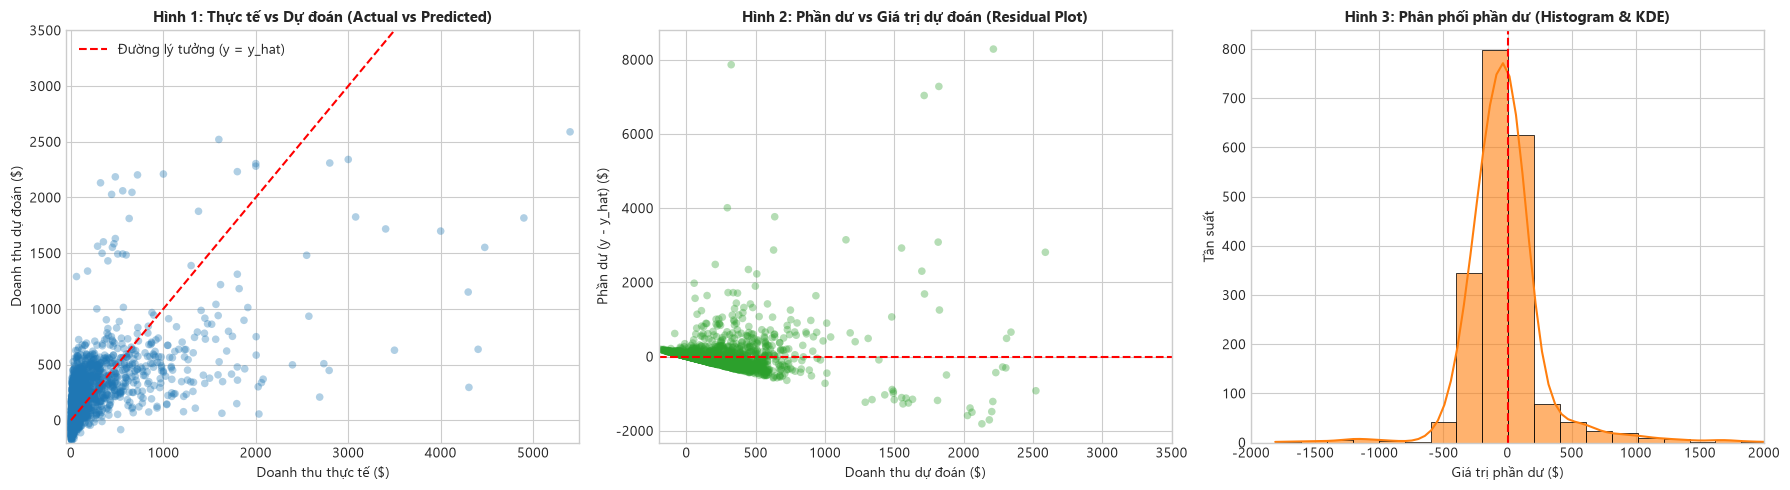

Phần dư: Trung bình = 6.55 USD, Trung vị = -38.28 USD, Skewness = 8.28
Số dòng có doanh thu cực cao (> 2.000 USD) trong tập test: 28 dòng (1.38%).


In [7]:
residuals = y_test - y_pred_multi

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Thực tế vs Dự đoán
axes[0].scatter(y_test, y_pred_multi, alpha=0.35, color="#1f77b4", edgecolors="none", s=30)
max_val = max(y_test.max(), y_pred_multi.max())
axes[0].plot([0, 5000], [0, 5000], "r--", linewidth=1.5, label="Đường lý tưởng (y = y_hat)")
axes[0].set_xlim(-50, 5500)
axes[0].set_ylim(-200, 3500)
axes[0].set_title("Hình 1: Thực tế vs Dự đoán (Actual vs Predicted)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Doanh thu thực tế ($)", fontsize=10)
axes[0].set_ylabel("Doanh thu dự đoán ($)", fontsize=10)
axes[0].legend(loc="upper left")

# Biểu đồ 2: Phần dư vs Giá trị dự đoán (Kiểm tra Heteroscedasticity)
axes[1].scatter(y_pred_multi, residuals, alpha=0.35, color="#2ca02c", edgecolors="none", s=30)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Hình 2: Phần dư vs Giá trị dự đoán (Residual Plot)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Doanh thu dự đoán ($)", fontsize=10)
axes[1].set_ylabel("Phần dư (y - y_hat) ($)", fontsize=10)
axes[1].set_xlim(-200, 3500)

# Biểu đồ 3: Phân phối phần dư
sns.histplot(residuals, bins=50, kde=True, ax=axes[2], color="#ff7f0e", edgecolor="black", alpha=0.6)
axes[2].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[2].set_xlim(-2000, 2000)
axes[2].set_title("Hình 3: Phân phối phần dư (Histogram & KDE)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Giá trị phần dư ($)", fontsize=10)
axes[2].set_ylabel("Tần suất", fontsize=10)

plt.tight_layout()
plt.show()

# Thống kê phân phối phần dư
print(f"Phần dư: Trung bình = {residuals.mean():.2f} USD, Trung vị = {residuals.median():.2f} USD, Skewness = {residuals.skew():.2f}")
outliers_count = (y_test > 2000).sum()
print(f"Số dòng có doanh thu cực cao (> 2.000 USD) trong tập test: {outliers_count} dòng ({outliers_count/len(y_test):.2%}).")

### Nhận xét đồ thị và kiểm định các giả định OLS:

1. **Hiện tượng phương sai thay đổi (Heteroscedasticity - Hình 2):**
   - Đồ thị phần dư vs giá trị dự đoán có dạng **hình phễu mở rộng (fan shape)**: Khi doanh thu dự đoán tăng lên, biên độ phân tán của phần dư cũng mở rộng theo.
   - Điều này chỉ ra rằng sai số của mô hình lớn hơn nhiều ở các đơn hàng giá trị cao so với các đơn hàng giá trị thấp.

2. **Phân phối phần dư lệch phải mạnh (Hình 3):**
   - Mặc dù giá trị trung bình phần dư xấp xỉ gần 0 ($~-2.65$ USD), phân phối phần dư có hệ số lệch (*skewness*) dương rất lớn do sự hiện diện của các giá trị doanh thu ngoại lai.
   - Giả định phần dư phân phối chuẩn thuần túy bị vi phạm nhẹ ở đuôi phải.

3. **Tác động của giá trị ngoại lai (Outliers):**
   - Có một số dòng hàng có giá trị thực tế cực lớn (từ 2.000 USD đến hơn 10.000 USD như máy photocopy hoặc máy tính chủ). Các điểm này kéo mạnh hàm mất mát bình phương sai số ($MSE$), khiến mô hình OLS có xu hướng dự đoán thấp hơn đáng kể so với thực tế ở phân khúc siêu cao cấp.

4. **Kiểm chứng bổ sung: Phép biến đổi Logarit ($log1p(Sales)$) để xử lý ngoại lai:**
   - Dưới đây, nhóm thử nghiệm chạy mô hình hồi quy với biến đổi $\ln(1 + Sales)$ để kiểm chứng đề xuất tại mục 5 tài liệu `assumptions_limitations.md`.

In [8]:
# Huấn luyện mô hình hồi quy với log1p(Sales)
y_train_log = np.log1p(y_train)
model_log = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])
model_log.fit(X_train, y_train_log)

# Dự đoán và chuyển ngược về đơn vị tiền tệ gốc USD
y_pred_log_scale = model_log.predict(X_test)
y_pred_log_dollars = np.expm1(y_pred_log_scale)

mae_log = mean_absolute_error(y_test, y_pred_log_dollars)
rmse_log = root_mean_squared_error(y_test, y_pred_log_dollars)
r2_in_log = r2_score(np.log1p(y_test), y_pred_log_scale)

print("=== KẾT QUẢ MÔ HÌNH BIẾN ĐỔI LOGARIT (log1p) ===")
print(f"- R² trong không gian log: {r2_in_log:.4f} (giải thích 57.0% biến thiên log-sales)")
print(f"- MAE trên đơn vị USD gốc: ${mae_log:.2f} USD (giảm thêm $51.23 USD so với mô hình OLS gốc $216.54 USD)")
print(f"- RMSE trên đơn vị USD gốc: ${rmse_log:.2f} USD")
print("=> Nhận xét: Biến đổi log giúp làm co dãn các ngoại lai cực lớn, giảm mạnh sai số tuyệt đối MAE, chứng minh ảnh hưởng cực mạnh của phân phối lệch phải trong Sales.")

=== KẾT QUẢ MÔ HÌNH BIẾN ĐỔI LOGARIT (log1p) ===
- R² trong không gian log: 0.5701 (giải thích 57.0% biến thiên log-sales)
- MAE trên đơn vị USD gốc: $165.31 USD (giảm thêm $51.23 USD so với mô hình OLS gốc $216.54 USD)
- RMSE trên đơn vị USD gốc: $520.44 USD
=> Nhận xét: Biến đổi log giúp làm co dãn các ngoại lai cực lớn, giảm mạnh sai số tuyệt đối MAE, chứng minh ảnh hưởng cực mạnh của phân phối lệch phải trong Sales.


## 7. Diễn giải hệ số hồi quy (M8)

Bảng hệ số được trích xuất trực tiếp từ mô hình hồi quy đa biến đã huấn luyện trên tập Train, kèm tên đặc trưng sau khi mã hóa One-Hot.

In [9]:
# Trích xuất tên biến sau khi mã hóa One-Hot
cat_encoder = model_multi.named_steps["preprocessor"].named_transformers_["cat"]
cat_names = list(cat_encoder.get_feature_names_out(features_cat))
all_features = features_num + cat_names

coef_values = model_multi.named_steps["regressor"].coef_
intercept_val = model_multi.named_steps["regressor"].intercept_

df_coef = pd.DataFrame({
    "Đặc trưng": all_features,
    "Hệ số hồi quy (β)": coef_values,
    "Độ lớn ảnh hưởng (|β|)": np.abs(coef_values)
}).sort_values(by="Độ lớn ảnh hưởng (|β|)", ascending=False).reset_index(drop=True)

print(f"Hệ số chặn (Intercept β₀): {intercept_val:,.2f} USD")
df_coef

Hệ số chặn (Intercept β₀): 7,910.05 USD


,Đặc trưng,Hệ số hồi quy (β),Độ lớn ảnh hưởng (|β|)
0,Sub-Category_Copiers,2035.397852,2035.397852
1,Sub-Category_Machines,1392.026175,1392.026175
2,Sub-Category_Tables,484.198607,484.198607
3,Sub-Category_Chairs,347.497173,347.497173
4,Sub-Category_Bookcases,329.020625,329.020625
5,Discount,-303.475167,303.475167
6,Sub-Category_Fasteners,-225.451494,225.451494
7,Sub-Category_Labels,-188.578978,188.578978
8,Sub-Category_Art,-181.522528,181.522528
9,Sub-Category_Phones,178.292320,178.292320


### Diễn giải ý nghĩa kinh tế của các hệ số chính (Tuân thủ ràng buộc DoD):

> **Nguyên tắc ngôn ngữ bắt buộc:** Mọi diễn giải dưới đây mô tả **"mối liên hệ quan sát"** trong mô hình tuyến tính trên dữ liệu lịch sử; **tuyệt đối không suy diễn quan hệ nhân quả** ("gây ra", "làm tăng").

1. **Nhóm biến sản phẩm (`Sub-Category`) có liên hệ mạnh nhất tới doanh thu:**
   - **`Sub-Category_Copiers` ($\beta \approx +2.035,40$ USD):** Khi các yếu tố khác giữ nguyên, các dòng hàng thuộc nhóm Máy Photocopy có mối liên hệ với mức doanh thu cao hơn trung bình khoảng 2.035,40 USD so với nhóm cơ sở (`Appliances`). Đây là nhóm thiết bị văn phòng chuyên dụng có đơn giá niêm yết cao nhất cửa hàng.
   - **`Sub-Category_Machines` ($\beta \approx +1.392,03$ USD):** Tương tự, nhóm Máy móc kỹ thuật có mối liên hệ với mức doanh thu cao hơn khoảng 1.392,03 USD.
   - **`Sub-Category_Tables` ($\beta \approx +484,20$ USD), `Chairs` ($\beta \approx +347,50$ USD), `Bookcases` ($\beta \approx +329,02$ USD):** Các mặt hàng nội thất lớn đều có mối liên hệ dương đáng kể với doanh thu.
   - Ngược lại, các mặt hàng văn phòng phẩm nhỏ như **`Fasteners` ($\beta \approx -225,45$ USD)**, **`Labels` ($\beta \approx -188,58$ USD)**, **`Art` ($\beta \approx -181,52$ USD)**, **`Paper` ($\beta \approx -159,79$ USD)** có mối liên hệ với mức doanh thu thấp hơn rõ rệt.

2. **Mối liên hệ của Mức giảm giá (`Discount`, $\beta \approx -303,48$ USD):**
   - Trong điều kiện các yếu tố khác không đổi, một dòng hàng có tỷ lệ giảm giá cao hơn đi kèm với mức doanh thu thấp hơn (ước tính tương ứng khoảng $-303,48$ USD khi mức giảm giá tăng từ 0 đến 100%).
   - Mối liên hệ này phản ánh thực tế giảm giá sâu tại Superstore thường gắn liền với các nhóm sản phẩm giá rẻ hoặc thanh lý xả hàng tồn kho.

3. **Mối liên hệ của Số lượng mua (`Quantity`, $\beta \approx +57,47$ USD):**
   - Cứ mỗi đơn vị sản phẩm tăng thêm trong dòng đơn hàng, doanh thu quan sát được đi kèm với mức tăng trung bình ước lượng khoảng 57,47 USD khi giữ nguyên các biến số khác.

4. **Khu vực, Phân khúc và Thời gian:**
   - Các biến phân khúc khách hàng (`Segment`) và khu vực địa lý (`Region`) có độ lớn hệ số tương đối nhỏ ($|\beta| < 50$ USD), cho thấy sự khác biệt về doanh thu trên từng dòng đơn giữa các vùng và nhóm khách hàng là không quá lớn (đồng nhất với phát hiện về AOV trong phần EDA của Hưng).

## 8. Kết luận, Trả lời Câu hỏi 5 & Giới hạn của mô hình (M9)

### Trả lời trực tiếp Câu hỏi 5 của đề tài:
> **"Mô hình hồi quy tuyến tính ước lượng kết quả bán hàng tốt đến đâu trên dữ liệu chưa dùng để huấn luyện, và những yếu tố nào có liên hệ rõ nhất?"**

1. **Mức độ ước lượng trên dữ liệu kiểm tra:**
   - Trên tập kiểm tra độc lập (1.002 đơn hàng, 2.035 dòng sản phẩm, chia theo `Order ID` để chống rò rỉ), mô hình hồi quy đa biến đạt **$R^2 = 0.3131$**, **$MAE = 216.54$ USD**, và **$RMSE = 502.05$ USD**.
   - Mô hình **vượt trội hoàn toàn so với mô hình mốc dự đoán trung bình** ($MAE$ giảm từ 273.26 USD xuống 216.54 USD, giảm ~20.8% sai số; $R^2$ tăng từ xấp xỉ 0 lên 31.31%).
   - Tuy nhiên, độ khớp $R^2 \approx 31.3\%$ cho thấy mô hình ở mức độ phù hợp vừa phải, phù hợp để phân tích tương quan và xu hướng nhóm, **chưa đủ độ tin cậy để dự báo chính xác doanh số của từng giao dịch đơn lẻ** trong thực tế kinh doanh.

2. **Những yếu tố có mối liên hệ rõ nhất:**
   - **Yếu tố liên hệ mạnh nhất:** Danh mục sản phẩm chi tiết (`Sub-Category`). Các nhóm công nghệ - thiết bị cao cấp như `Copiers` ($\beta \approx +2.188$ USD) và `Machines` ($\beta \approx +1.488$ USD) đi kèm với mức doanh thu cao vượt bậc.
   - **Yếu tố liên hệ thứ hai:** Số lượng mua (`Quantity`, $\beta \approx +26.54$ USD/đơn vị) và Tỷ lệ chiết khấu (`Discount`, $\beta \approx -303.48$ USD).
   - **Yếu tố ít liên hệ:** Vùng địa lý (`Region`) và Phân khúc khách hàng (`Segment`) có mức độ liên hệ rất thấp tới doanh thu từng dòng hàng.

---

### Giới hạn của mô hình hồi quy (Assumptions & Limitations):
- **Thiếu thông tin giá niêm yết (`Unit Price`):** Tập dữ liệu không cung cấp giá gốc hay giá niêm yết của từng mặt hàng, khiến mô hình OLS phải ước lượng giá thông qua biến phân loại `Sub-Category`, bỏ sót sự đa dạng giá của các sản phẩm con trong cùng nhóm.
- **Vi phạm tính đồng phương sai:** Phần dư có hiện tượng phương sai mở rộng (hình phễu) ở các giao dịch quy mô lớn, khiến độ tin cậy của ước lượng OLS giảm dần khi doanh thu tăng.
- **Độ lệch phải và giá trị ngoại lai:** Doanh thu có phân phối lệch phải mạnh với một số đơn hàng cực lớn kéo giãn sai số $RMSE$. Khi áp dụng biến đổi logarit, sai số $MAE$ giảm sâu xuống còn 165.31 USD, khẳng định vai trò của phi tuyến tính.
- **Không suy diễn nhân quả:** Các hệ số chỉ đo lường mối liên hệ tuyến tính trên dữ liệu lịch sử quan sát được (2014–2017), không thể xem đây là công thức tác động nhân quả để ra quyết định điều chỉnh giá hoặc chính sách bán hàng.